In [300]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const

from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [318]:
data, var = load_data_and_var()

In [405]:
nfws_full=generate_nfws_from_combined_dataset_werr(data, var)

In [406]:
nfws = [nfw for nfw in nfws_full if nfw.z < 0.2]

In [407]:
test_nfw=nfws[0]

In [23]:
zs = [nfw.z for nfw in nfws]

In [98]:
th_es = np.array([nfw.energies.thermal_energy for nfw in nfws])

In [99]:
p_es = np.array([nfw.energies.abs_potential_energy for nfw in nfws])

In [100]:
virialization_ratio = 2*th_es/p_es

Text(0, 0.5, '2*Eth/Ep')

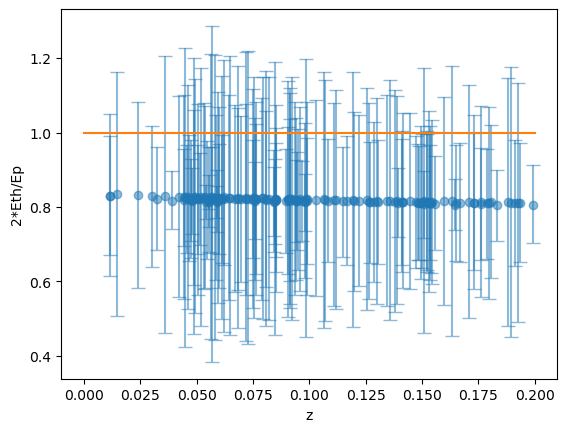

In [101]:
plt.errorbar(zs, virialization_ratio,
             yerr=[[v.minus for v in virialization_ratio],[v.plus for v in virialization_ratio]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5)
plt.plot([0,0.2], [1, 1])

plt.xlabel('z')
plt.ylabel('2*Eth/Ep')

Text(0, 0.5, '2*Eth/Ep')

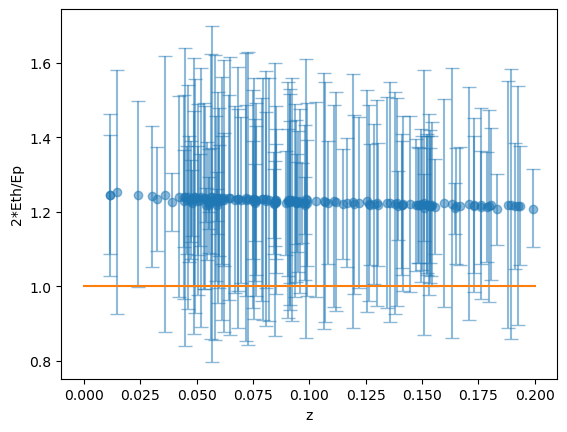

In [93]:
plt.errorbar(zs, virialization_ratio/(2./3.),
             yerr=[[v.minus for v in virialization_ratio],[v.plus for v in virialization_ratio]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5)
plt.plot([0,0.2], [1, 1])

plt.xlabel('z')
plt.ylabel('2*Eth/Ep')

In [49]:
np.divide(np.multiply(th_es, 2), p_es)

array([<asymmetric_uncertainty_mod.core.a_u object at 0x12d1fcb90>,
      dtype=object)

In [50]:
zs

[0.0924,
 0.1147,
 0.062,
 0.094,
 0.1599,
 0.141,
 0.0491,
 0.1448,
 0.112,
 0.0555,
 0.1082,
 0.0442,
 0.0569,
 0.0533,
 0.0238,
 0.045,
 0.0519,
 0.1168,
 0.1805,
 0.1529,
 0.0907,
 0.0685,
 0.0718,
 0.0752,
 0.0643,
 0.0853,
 0.1729,
 0.103,
 0.059,
 0.057,
 0.0613,
 0.06,
 0.0589,
 0.0326,
 0.067,
 0.072,
 0.1501,
 0.0536,
 0.0912,
 0.0756,
 0.1913,
 0.1706,
 0.154,
 0.0915,
 0.0358,
 0.1254,
 0.1483,
 0.042,
 0.0989,
 0.0468,
 0.1392,
 0.152,
 0.0514,
 0.0506,
 0.1759,
 0.1644,
 0.0822,
 0.0542,
 0.1535,
 0.1634,
 0.1669,
 0.0445,
 0.0586,
 0.065,
 0.1342,
 0.1416,
 0.1306,
 0.1195,
 0.0697,
 0.1557,
 0.0685,
 0.1268,
 0.1992,
 0.1797,
 0.0114,
 0.0114,
 0.0462,
 0.0544,
 0.0473,
 0.0554,
 0.0845,
 0.0845,
 0.0847,
 0.1288,
 0.1832,
 0.1892,
 0.1926,
 0.0458,
 0.048,
 0.0852,
 0.049,
 0.1264,
 0.0765,
 0.0391,
 0.1198,
 0.1533,
 0.0912,
 0.0146,
 0.0726,
 0.06,
 0.1069,
 0.1728,
 0.1496,
 0.0556,
 0.138,
 0.0505,
 0.0936,
 0.0894,
 0.1475,
 0.139,
 0.188,
 0.0487,
 0.1651,
 0.152

In [128]:
test_nfw.energies.T500


In [129]:
T500s_gaspari = np.array([nfw.energies.T500 for nfw in nfws])

In [130]:
T500s_iqbal = np.array([nfw.Tbs[-1] for nfw in nfws])

Text(0, 0.5, 'gaspari T500 (GeV)')

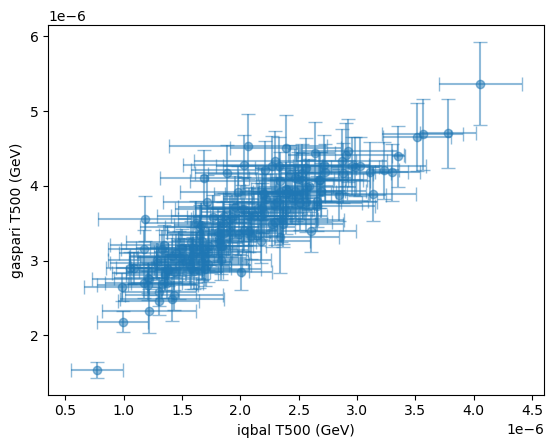

In [143]:
plt.errorbar(T500s_iqbal, T500s_gaspari,
            xerr=[[v.minus for v in T500s_iqbal],[v.plus for v in T500s_iqbal]],
            yerr =[[v.minus for v in T500s_gaspari],[v.plus for v in T500s_gaspari]],
             fmt='o', capsize=5, capthick=1, alpha=0.5
            )
#plt.xscale('log')
#plt.yscale('log')
plt.xlabel('iqbal T500 (GeV)')
plt.ylabel('gaspari T500 (GeV)')

Text(0, 0.5, 'gaspari T500/iqbal T500')

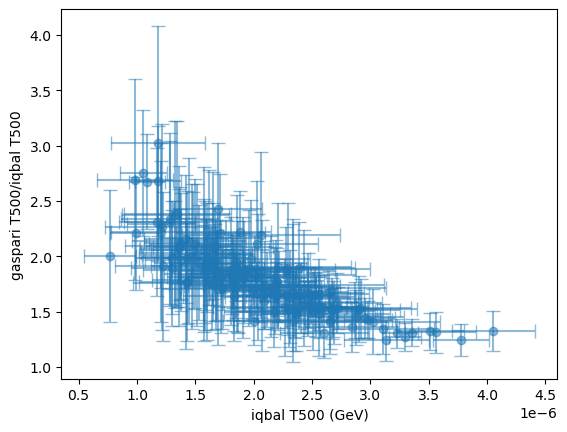

In [144]:
plt.errorbar(T500s_iqbal, T500s_gaspari/T500s_iqbal,
            xerr=[[v.minus for v in T500s_iqbal],[v.plus for v in T500s_iqbal]],
            yerr =[[v.minus for v in T500s_gaspari/T500s_iqbal],[v.plus for v in T500s_gaspari/T500s_iqbal]],
             fmt='o', capsize=5, capthick=1, alpha=0.5
            )
#plt.yscale('log')
plt.xlabel('iqbal T500 (GeV)')
plt.ylabel('gaspari T500/iqbal T500')

TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

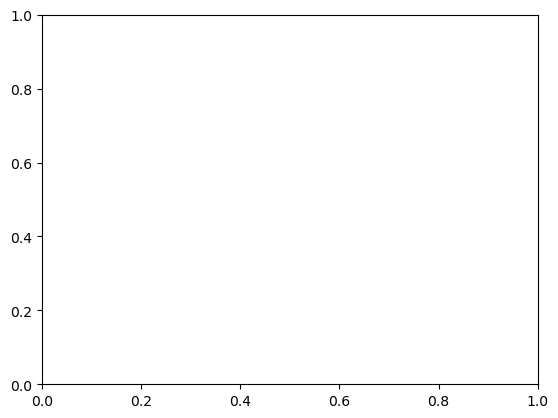

In [136]:
plt.hist(T500s_gaspari/T500s_iqbal)

In [147]:
th_es_g = np.array([nfw.energies.thermal_energy_gaspari for nfw in nfws])
virialization_ratio_gaspari = 2*th_es_g/p_es

Text(0, 0.5, '2*Eth(Gaspari T500)/Ep')

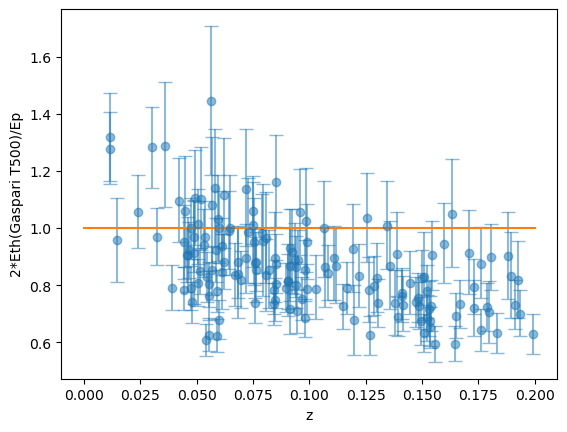

In [149]:
plt.errorbar(zs, virialization_ratio_gaspari,
             yerr=[[v.minus for v in virialization_ratio_gaspari],[v.plus for v in virialization_ratio_gaspari]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5)
plt.plot([0,0.2], [1, 1])

plt.xlabel('z')
plt.ylabel('2*Eth(Gaspari T500)/Ep')

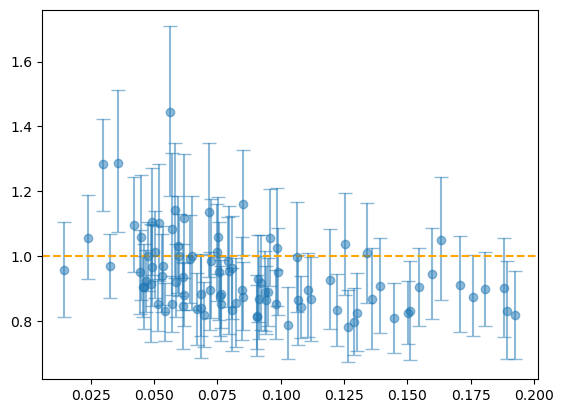

In [161]:
# Assuming you have data and error like this:
data = np.array(nfws)
#error = np.array([v.plus if v<1 else v.minus for v in virialization_ratio_gaspari])

# Calculate the lower and upper bounds of the error bars
#lower_bound = data - 2 * error
#upper_bound = data + 2 * error

# Create a mask for the points within 2 times their error bar of 1.0
mask = (lower_bound <= 1.0) & (1.0 <= upper_bound)


nfws_subset = [nfw for nfw in nfws if nfw.energies.is_virialized ]

# Filter the data and error using the mask
filtered_data = [nfw.energies.virialization_fraction_gaspari for nfw in nfws_subset]
#filtered_error = error[mask]

# Create the plot
plt.errorbar([nfw.z for nfw in nfws_subset], filtered_data, 
             yerr=[[v.minus for v in filtered_data],[v.plus for v in filtered_data]], fmt='o', capsize=5, capthick=1, alpha=0.5)
plt.axhline(1.0, color='orange', linestyle='--')  # Add a horizontal line at y=1.0
plt.show()

In [163]:
len(nfws_subset), len(nfws)

(94, 154)

In [174]:
test_nfw

In [201]:

test_nfw.T_g(test_nfw.R500)

0.8964501279607096 (+0.03766084593701641, -0.04023528028785696)
4.785415841587843e-20
1.0713464565334978e-05 (+1.8248834901376976e-06, -1.89419611179967e-06)
0.8964501279607096 (+0.03766084593701641, -0.04023528028785696)
4.785415841587843e-20
1.0713464565334978e-05 (+1.8248834901376976e-06, -1.89419611179967e-06)


In [200]:
print(test_nfw.rho_g(test_nfw.R500))

0.8964501279607096 (+0.03766084593701641, -0.04023528028785696)
4.785415841587843e-20
1.0713464565334978e-05 (+1.8248834901376976e-06, -1.89419611179967e-06)
7119814127118.507 (+1393735225475.2673, -1370857036482.2932)


In [217]:
thermal_energies = np.array([nfw.energies.thermal_energy for nfw in nfws])

In [219]:
potential_energies = np.array([nfw.energies.abs_potential_energy for nfw in nfws])

In [211]:
print(rs[-1])

0.8964501279607096 (+0.03766084593701641, -0.04023528028785696)


In [212]:
test_nfw.dP_dr(rs)

In [214]:
test_nfw.rho_g(test_nfw.R500)

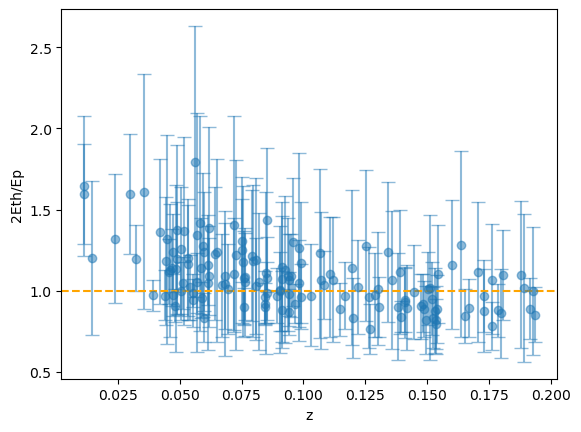

In [225]:
# Assuming you have data and error like this:
data = np.array(nfws)
#error = np.array([v.plus if v<1 else v.minus for v in virialization_ratio_gaspari])

# Calculate the lower and upper bounds of the error bars
#lower_bound = data - 2 * error
#upper_bound = data + 2 * error

# Create a mask for the points within 2 times their error bar of 1.0
mask = (lower_bound <= 1.0) & (1.0 <= upper_bound)


nfws_subset = [nfw for nfw in nfws if nfw.energies.is_virialized_iqbal ]

# Filter the data and error using the mask
filtered_data = [nfw.energies.virialization_fraction_iqbal for nfw in nfws_subset]
#filtered_error = error[mask]

# Create the plot
plt.errorbar([nfw.z for nfw in nfws_subset], filtered_data, 
             yerr=[[v.minus for v in filtered_data],[v.plus for v in filtered_data]], fmt='o', capsize=5, capthick=1, alpha=0.5)
plt.axhline(1.0, color='orange', linestyle='--')  # Add a horizontal line at y=1.0

plt.xlabel('z')
plt.ylabel('2Eth/Ep')
plt.show()

In [224]:
len(nfws_subset), len(nfws)

(145, 154)

In [230]:
print(test_nfw.total_cooling_rate(0.001*test_nfw.R500, test_nfw.R500))

9.053025356744835e+44 (+1.4385762112766871e+44, -1.4451842714129785e+44)


In [231]:
print(test_nfw.total_cooling_rate(0.001*test_nfw.R500, test_nfw.R500, match_gaspari=False))

8.188335573067685e+44 (+1.3542330503066698e+44, -1.3601556813170455e+44)


In [232]:
tot_rad_iq = [n.total_cooling_rate(0.001*n.R500, n.R500, match_gaspari=False) for n in nfws_subset]

In [233]:
tot_rad_ga = [n.total_cooling_rate(0.001*n.R500, n.R500, match_gaspari=True) for n in nfws_subset]

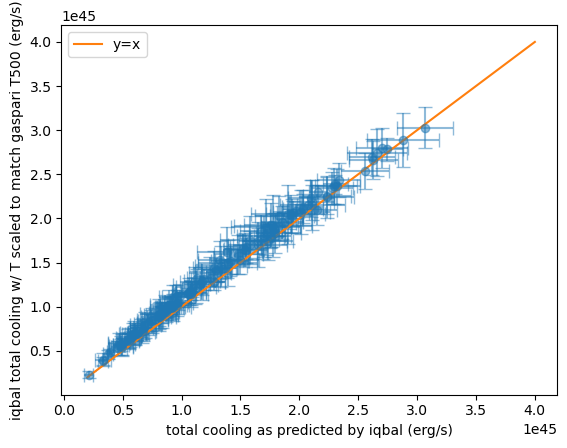

In [246]:
plt.errorbar(tot_rad_iq, tot_rad_ga, 
            yerr=[[v.minus for v in tot_rad_ga],[v.plus for v in tot_rad_ga]],
             xerr=[[v.minus for v in tot_rad_iq],[v.plus for v in tot_rad_iq]],
             fmt='o', capsize=5, capthick=1, alpha=0.5)
plt.plot([2e44,4e45], [2e44,4e45], label="y=x")
#plt.xscale('log')
#plt.yscale('log')
plt.xlabel('total cooling as predicted by iqbal (erg/s)')
plt.ylabel('iqbal total cooling w/ T scaled to match gaspari T500 (erg/s)')
plt.legend()

<ErrorbarContainer object of 3 artists>

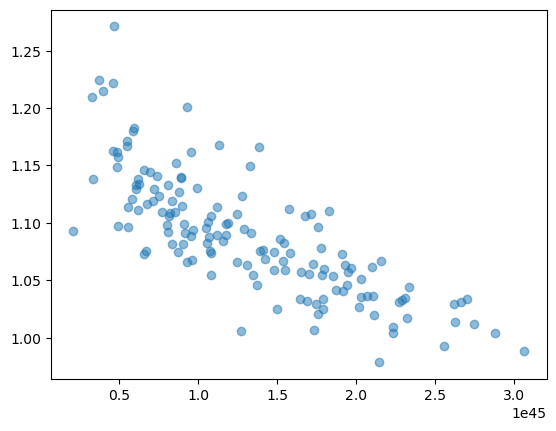

In [248]:
plt.errorbar(tot_rad_iq, np.divide(tot_rad_ga, tot_rad_iq), 
            #yerr=[[v.minus for v in tot_rad_ga],[v.plus for v in tot_rad_ga]],
             #xerr=[[v.minus for v in tot_rad_iq],[v.plus for v in tot_rad_iq]],
             fmt='o', capsize=5, capthick=1, alpha=0.5)

In [259]:
iqbal_T500s = [n.T_g(n.R500, match_gaspari=False) for n in nfws]

In [260]:
gaspari_T500s = [n.T_g(n.R500, match_gaspari=True) for n in nfws]

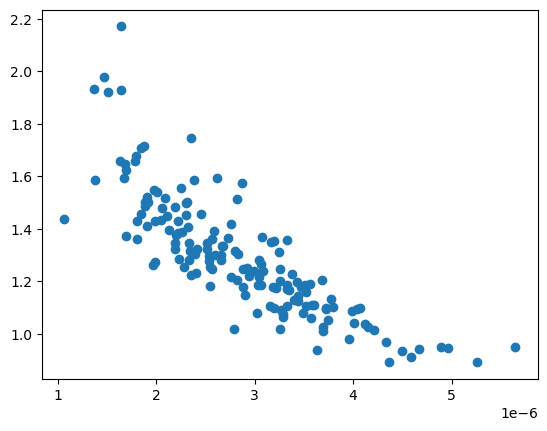

In [261]:
plt.scatter(iqbal_T500s, np.divide(gaspari_T500s,iqbal_T500s))

In [264]:
np.shape(nfws)

(154,)

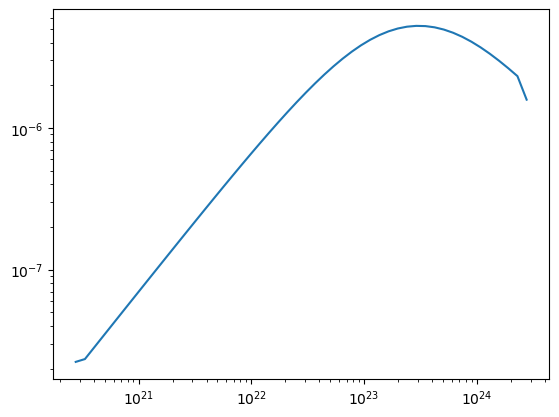

In [268]:
plt.loglog(test_nfw.rvals, test_nfw.Tbs)

In [273]:
u.GeV.to(u.K, equivalencies=u.temperature_energy())

11604518121550.08

In [278]:
rmin = 0.01*test_nfw.R500
rmax = test_nfw.R500
xmin = rmin.value/test_nfw.R500.value
xmax = rmax.value/test_nfw.R500.value
xs = np.logspace(np.log10(xmin), np.log10(xmax), num=50)
rs = xs*test_nfw.R500

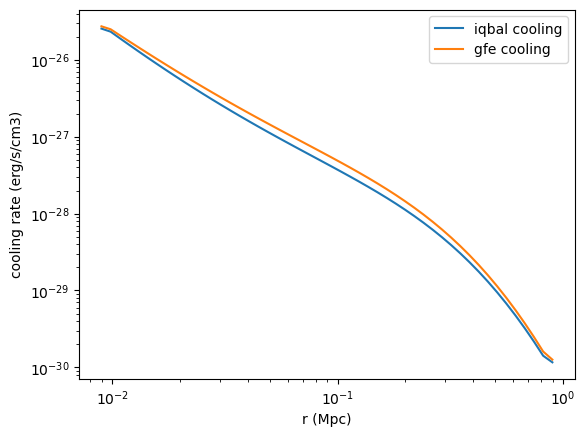

In [308]:
plt.loglog(rs, test_nfw.vol_cooling_rate(rs), label='iqbal cooling')
plt.loglog(rs, 2*test_nfw.vol_radiative_cooling_rate_gfe(rs), label='gfe cooling')

plt.xlabel('r (Mpc)')
plt.ylabel('cooling rate (erg/s/cm3)')
plt.legend()

In [305]:
print(np.divide(test_nfw.vol_cooling_rate(rs), test_nfw.vol_radiative_cooling_rate_gfe(rs))[0])

1.867559607728662 ± 25.41910687765808


In [286]:
(u.Mpc/u.cm).to(1)

3.085677581491367e+24

In [291]:
u.erg.to(u.GeV)

624.1509074460764

In [298]:
u.GeV.to(u.K, equivalencies=u.temperature_energy())

11604518121550.08

In [301]:
(const.k_B/const.h).value

<Quantity 2.08366191e+10 1 / (K s)>

In [303]:
const.h.to(u.erg*u.s)

<Quantity 6.62607015e-27 erg s>

In [310]:
print(test_nfw.total_cooling_rate(rmin, rmax, vol_rate='iqbal'))

8.760024680986224e+44 (+1.3498499162709308e+44, -1.356148260199078e+44)


In [312]:
print(test_nfw.total_cooling_rate(rmin, rmax, vol_rate='gfe'))

5.430583225978066e+44 (+8.442298099803403e+43, -8.479446582301266e+43)


TypeError: Cluster_werr.__init__() missing 1 required positional argument: 'z'

In [415]:
from cluster_functions import c
GeV_to_erg = (u.GeV).to(u.erg)
mp_GeV = (const.m_p).to(u.GeV).value
c0 = c(0) * (const.c.to(u.cm / u.s)).value

mx = 1e-2
s0=1e-30
s0_factors = (3*c0*s0/(((mx + mp_GeV) ** 2)) * GeV_to_erg)
import time
start_time = time.time()
print(test_nfw.L500_numerical(mx, s0))
end_time = time.time()
print(end_time-start_time)

(3.84888197589729e+44, 1.808866843733318e+45)
1.8299510478973389


In [366]:
test_nfw.L500

In [376]:
import cProfile
import pstats

profiler = cProfile.Profile()
profiler.enable()

# Call the function
print(test_nfw.L500_numerical(mx, s0))

profiler.disable()
stats = pstats.Stats(profiler).sort_stats('cumtime')
stats.print_stats()

(1.8178180138264895e+44, 4.266591226955981e+44)
         3365485 function calls (3357751 primitive calls) in 4.081 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.001    0.001    4.080    2.040 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3490(run_code)
        2    0.001    0.000    4.078    2.039 {built-in method builtins.exec}
        1    0.000    0.000    4.077    4.077 /var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_45314/3389972773.py:1(<module>)
        1    0.000    0.000    4.071    4.071 /Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_error_prop.py:406(L500_numerical)
        3    0.002    0.001    4.069    1.356 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/scipy/optimize/_zeros_py.py:672(brentq)
        3    0.001    0.000    4.067    1.356 {built-in method scipy.optimize._zeros._brentq}
   

In [416]:
import cProfile
import pstats

profiler = cProfile.Profile()
profiler.enable()

# Call the function
print(test_nfw.L500_numerical(mx, s0))

profiler.disable()
stats = pstats.Stats(profiler).sort_stats('cumtime')
stats.print_stats()

(3.8488819758972525e+44, 1.8746554145520258e+45)
         1270337 function calls (1267934 primitive calls) in 1.419 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    1.419    0.710 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3490(run_code)
        2    0.000    0.000    1.419    0.710 {built-in method builtins.exec}
        1    0.000    0.000    1.419    1.419 /var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_45314/3389972773.py:1(<module>)
        1    0.000    0.000    1.418    1.418 /Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_error_prop.py:408(L500_numerical)
        3    0.000    0.000    1.417    0.472 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/scipy/optimize/_zeros_py.py:672(brentq)
        3    0.000    0.000    1.417    0.472 {built-in method scipy.optimize._zeros._brentq}
  

In [373]:
test_nfw.L500_numerical(mx, 1e-40)

(1.817679971600248e+44, 1.554075252563541e+44)

In [357]:
test_nfw.L500

In [388]:
test_nfw.T500

In [408]:
print(test_nfw.rad_factors)

1.0644290395990223e+41 (+1.6705477979470595e+40, -1.678377036531758e+40)


In [420]:
Ls = np.logspace(40, 50)
net_heatings = test_nfw.L500_numerical(1e-2, 1e-30)

In [436]:
net_heatings_35=test_nfw.L500_numerical(1e-2, 1e-35)

In [434]:
net_heatings_25 = test_nfw.L500_numerical(1e-2, 1e-25)

In [443]:
net_heatings_26 = test_nfw.L500_numerical(1e-2, 1e-26)

In [444]:
net_heatings_27 = test_nfw.L500_numerical(1e-2, 1e-27)

In [446]:
net_heatings_27_4 = test_nfw.L500_numerical(1e-4, 1e-27)

In [422]:
net_heatings

[-2.2826471761459094e+44,
 -2.38003287077812e+44,
 -2.47861418774573e+44,
 -2.5777121714294964e+44,
 -2.6764684428098348e+44,
 -2.7738077335464773e+44,
 -2.8683929731791647e+44,
 -2.9585714673075055e+44,
 -3.0423104184338247e+44,
 -3.1171196990143945e+44,
 -3.17995937721893e+44,
 -3.2271290068651577e+44,
 -3.254135108334808e+44,
 -3.2555325682939775e+44,
 -3.2247348503819677e+44,
 -3.1537869099776416e+44,
 -3.033093511754508e+44,
 -2.8510942208041593e+44,
 -2.593874630984445e+44,
 -2.244701353248744e+44,
 -1.78346584678083e+44,
 -1.1860192587817045e+44,
 -4.2337695146407425e+43,
 5.392327742911279e+43,
 1.7435062333756133e+44,
 3.239424622432466e+44,
 5.08688055448161e+44,
 7.357622935710025e+44,
 1.013758243939383e+45,
 1.3529652003919933e+45,
 1.7657011333603244e+45,
 2.2667101777685044e+45,
 2.8736378760772986e+45,
 3.6075993801961975e+45,
 4.493858788493752e+45,
 5.562641347783584e+45,
 6.850104498569681e+45,
 8.399498820829083e+45,
 1.0262556009571439e+46,
 1.2501148268481314e+46,

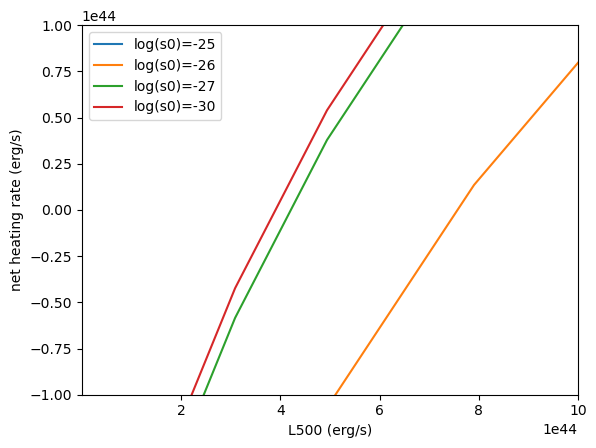

In [460]:
plt.plot(Ls, net_heatings_25, label='log(s0)=-25')
plt.plot(Ls, net_heatings_26, label='log(s0)=-26')
plt.plot(Ls, net_heatings_27, label='log(s0)=-27')
#plt.plot(Ls, net_heatings_27_4, label='log(s0)=-27, mx=4')
plt.plot(Ls, net_heatings, label='log(s0)=-30')
#plt.plot(Ls, net_heatings_35, label='log(s0)=-35')
#plt.xscale('log')
#plt.yscale('symlog')
plt.xlabel('L500 (erg/s)')
plt.ylabel('net heating rate (erg/s)')
plt.xlim(1e40, 1e45)
plt.ylim(-1e44, 1e44)
plt.legend()

In [418]:
Ls

array([1.00000000e+40, 1.59985872e+40, 2.55954792e+40, 4.09491506e+40,
       6.55128557e+40, 1.04811313e+41, 1.67683294e+41, 2.68269580e+41,
       4.29193426e+41, 6.86648845e+41, 1.09854114e+42, 1.75751062e+42,
       2.81176870e+42, 4.49843267e+42, 7.19685673e+42, 1.15139540e+43,
       1.84206997e+43, 2.94705170e+43, 4.71486636e+43, 7.54312006e+43,
       1.20679264e+44, 1.93069773e+44, 3.08884360e+44, 4.94171336e+44,
       7.90604321e+44, 1.26485522e+45, 2.02358965e+45, 3.23745754e+45,
       5.17947468e+45, 8.28642773e+45, 1.32571137e+46, 2.12095089e+46,
       3.39322177e+46, 5.42867544e+46, 8.68511374e+46, 1.38949549e+47,
       2.22299648e+47, 3.55648031e+47, 5.68986603e+47, 9.10298178e+47,
       1.45634848e+48, 2.32995181e+48, 3.72759372e+48, 5.96362332e+48,
       9.54095476e+48, 1.52641797e+49, 2.44205309e+49, 3.90693994e+49,
       6.25055193e+49, 1.00000000e+50])